# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'   # [정답안] 예시 번호
if not student_id or not student_id.isascii() or not student_id.isdigit():  # 비어 있거나, 영숫자 외 문자가 있거나, 숫자가 아니면 오류
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')  # 수험번호 형식 오류를 알리고 실행을 멈춤
print('수험번호:', student_id)  # 입력한 수험번호를 화면에 출력

수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 1-2. (예측)

> **[예측 문제]** 공식 샘플의 형식·제약을 그대로 따르고 데이터와 함정만 바꾼 연습 문제입니다. 실제 시험 문제가 아닙니다.

> 우리 쇼핑몰은 상품 사진으로 카테고리를 자동 분류한다. 학습 데이터는 **스튜디오에서 찍은 정돈된 상품컷**(흰 배경, 가운데, 꽉 찬 크기)이다. \
> 이번에 **판매자 앱 업로드 기능**이 열리면서, 판매자가 직접 찍은 사진이 들어오기 시작했다. 이 사진들은 상품이 작게 찍히거나, 한쪽에 치우치거나, 기울어지거나, 어둡거나, 흑백인 경우가 있다.

검증(`val`) 데이터는 **판매자 앱 업로드 사진**에서 뽑았습니다. 학습 데이터는 바꿀 수 없고, **학습용 변환(`train_transform`)만** 수정할 수 있습니다.

## 공통 조건
- 모델은 TinyViT 5M `dist_in22k_ft_in1k`, **Full Fine-Tuning**, 구조·epoch(12)·학습률·batch·Loss는 고정입니다.
- 입력은 **높이 80 × 너비 60 RGB**로 유지합니다(텐서 변환과 정규화도 유지).
- train / val 구분과 정답은 변경하지 마세요.

## 평가 지표
- 최하단 `[Final] Validation macro-F1` 기준: High 0.80 초과 / Mid 0.60 초과 0.80 이하 / Low 0.60 이하

> ## [예측 문제 정답안]
> val(앱 사진)의 축소·이동·회전·조명·흑백을 증강으로 재현, 해로운 기본 변환 제거

참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정

아래 셀은 가상환경이 설정되어 있으며 커널이 해당 가상환경으로 잡혀 있는지를 체크합니다.
꼭 실행해서 확인 후에 진행하세요. 오류가 발생하면 이 폴더의 README.md를 참고해 환경을 다시 확인하세요.
특히 VS Code, PyCharm 환경에서 Jupyter Notebook 커널을 꼭 확인하세요.


In [2]:
# [정답안] 환경 확인 - CPU/GPU 겸용 (문제 노트북은 GPU가 없으면 여기서 멈춥니다)
import sys  # 파이썬 인터프리터 정보(sys.prefix, sys.executable)를 쓰기 위한 모듈
from pathlib import Path  # 경로를 객체로 다루는 Path 클래스

print('Python:', sys.version.split()[0])  # 현재 파이썬 버전 출력 (예: 3.12.10)
print('현재 커널:', sys.executable)  # 지금 노트북을 실행 중인 python.exe 경로 출력 → .venv인지 확인
print('작업 폴더:', Path.cwd())  # 현재 작업 폴더 출력 (상대 경로 data/... 의 기준)
expected_env = Path.cwd() / '.venv'  # 작업 폴더 아래 .venv 폴더 경로를 기대값으로 만듦
if Path(sys.prefix).resolve() != expected_env.resolve():  # 실행 중인 파이썬의 환경 폴더가 기대한 .venv와 다르면
    raise RuntimeError(f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요.")  # 잘못된 커널 오류
import torch, torchvision, timm  # 세 라이브러리 한 번에 불러오기
print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)  # 설치된 세 라이브러리 버전 출력
if torch.cuda.is_available():  # CUDA GPU를 쓸 수 있으면
    DEVICE, QUICK = 'cuda', False  # 장치는 GPU, QUICK(축소 실행) 모드는 끔
    print('GPU:', torch.cuda.get_device_name(0), '-> 원본 설정 그대로 실행합니다.')  # GPU 이름 출력
else:  # 그렇지 않으면 (아래 실행)
    DEVICE, QUICK = 'cpu', True  # 장치는 CPU, QUICK 모드 켬 → 뒤의 [정답안 전용] 셀이 데이터·epoch를 줄임
    print('GPU 없음 -> QUICK 모드: 학습 데이터와 epoch를 줄여 CPU에서 끝까지 실행합니다 (점수는 낮게 나옴).')  # CPU 실행 안내

Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_final_predict


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
GPU: NVIDIA GeForce RTX 5060 Ti -> 원본 설정 그대로 실행합니다.


In [3]:
# 수정 금지

from pathlib import Path  # 경로를 객체로 다루는 Path 클래스
import random  # 파이썬 기본 난수 (시드 고정용)
import json  # JSON 파일(classes.json) 읽기용
import time  # 학습 시간 측정용

import numpy as np  # NumPy: 이미지 배열(N, H, W, 3) 처리
import matplotlib.pyplot as plt  # 그래프 그리기
import torch  # PyTorch: 텐서 연산·자동 미분·신경망
from torch import nn  # nn: 신경망 층(Linear, Conv2d 등)과 Loss 클래스
from torch.nn import functional as F  # F: 함수형 API (interpolate, log_softmax, pad 등)
from torch.utils.data import Dataset, DataLoader  # Dataset(데이터 한 개 꺼내기 규칙), DataLoader(배치로 묶기)
from torchvision import transforms as T  # 이미지 변환 모음을 T라는 이름으로 사용 (V1 API)
from sklearn.metrics import f1_score  # F1 점수 계산 함수

random.seed(42)  # 파이썬 random 시드 고정 → 실행마다 같은 결과
np.random.seed(42)  # NumPy 난수 시드 고정
torch.manual_seed(42)  # PyTorch 난수 시드 고정 (가중치 초기화, shuffle 순서)

device = 'cuda' if torch.cuda.is_available() else 'cpu'  # GPU가 있으면 'cuda', 없으면 'cpu'를 장치로 사용
print('사용 장치:', torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU')  # 사용 장치 이름 출력


사용 장치: NVIDIA GeForce RTX 5060 Ti


In [4]:
# 수정 금지

data_path = Path('data/f1_2_shift/prepared.npz')  # F1_2 데이터 파일
if not data_path.is_file() or not data_path.with_name('classes.json').is_file():  # npz 파일이나 같은 폴더의 classes.json이 없으면
    raise FileNotFoundError('데이터가 없습니다. 먼저 setup.cmd를 실행하고, 작업 폴더를 이 노트북이 있는 폴더로 맞추세요.')  # 데이터 준비가 안 됐다는 오류

In [5]:
# 수정 금지

with data_path.with_name('classes.json').open(encoding='utf-8') as file:  # classes.json을 UTF-8로 열기 (with: 끝나면 자동으로 닫힘)
    class_names = json.load(file)  # 클래스 이름 목록 읽기 (목록 순서 = 클래스 번호)
num_classes = len(class_names)  # 클래스 개수

with np.load(data_path, allow_pickle=False) as data:  # npz 열기 (allow_pickle=False: 안전하게 배열만 읽음)
    train_images = data['train_images']  # 학습 이미지 배열 (N, 80, 60, 3) uint8
    train_labels = data['train_labels'].reshape(-1)  # (N,1)이어도 (N,)으로 펼침
    val_images = data['val_images']  # 검증 이미지 배열
    val_labels = data['val_labels'].reshape(-1)  # (N,)으로 펼침

print('클래스:', num_classes)  # 클래스 수 출력
print('학습:', len(train_images), '검증:', len(val_images))  # 개수 출력
print('이미지 크기:', train_images[0].shape)  # 이미지 크기 출력


클래스: 20
학습: 5000 검증: 2000
이미지 크기: (80, 60, 3)


> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [6]:
# [정답안 전용] CPU QUICK 모드에서만 데이터를 줄입니다.
if QUICK:  # CPU(QUICK) 모드일 때만
    _rng = np.random.default_rng(0)  # QUICK용 난수 생성기
    _keep = np.sort(_rng.choice(len(train_labels), size=min(2500, len(train_labels)), replace=False))  # QUICK: 학습 2,500개
    train_images, train_labels = train_images[_keep], train_labels[_keep]  # 뽑은 것만 남김
    _keep = np.sort(_rng.choice(len(val_labels), size=min(800, len(val_labels)), replace=False))  # QUICK: 검증 800개
    val_images, val_labels = val_images[_keep], val_labels[_keep]  # 뽑은 검증만 남김
    print('QUICK 모드 데이터:', len(train_labels), len(val_labels))  # 줄인 개수 출력

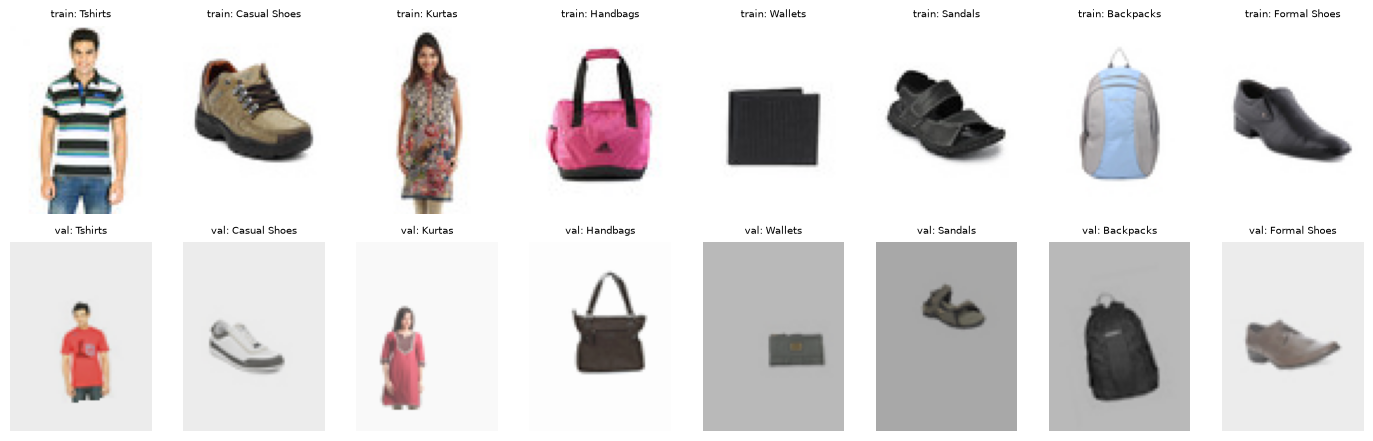

In [7]:
# 수정 가능
# 확인용 그림입니다. 자유롭게 고쳐서 데이터를 살펴보세요.
fig, axes = plt.subplots(2, 8, figsize=(14, 4.5))  # 2×8 격자
for axis, index in zip(axes[0], range(0, len(train_labels), len(train_labels) // 8)):  # 학습 이미지를 고르게 8장
    axis.imshow(train_images[index]); axis.set_title('train: ' + class_names[train_labels[index]], fontsize=7)  # 이미지와 제목 표시
for axis, index in zip(axes[1], range(0, len(val_labels), len(val_labels) // 8)):  # 검증 이미지를 고르게 8장
    axis.imshow(val_images[index]); axis.set_title('val: ' + class_names[val_labels[index]], fontsize=7)  # 이미지와 제목 표시
for axis in axes.flat:  # 모든 칸에 대해
    axis.axis('off')  # 축 눈금·테두리 숨김
plt.tight_layout()  # 여백 자동 정리
plt.show()  # 그림 표시

In [8]:
# 수정 금지

mean = (0.485, 0.456, 0.406)  # ImageNet 채널별 평균 (사전학습 때 쓴 값)
std = (0.229, 0.224, 0.225)  # ImageNet 채널별 표준편차
eval_transform = T.Compose([  # 평가용 변환: 증강 없이 텐서 변환 + 정규화만
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
])


In [9]:
# 수정 금지

class FashionDataset(Dataset):  # 이미지·라벨·증강 여부로 샘플을 꺼내는 Dataset
    def __init__(self, images, labels, transform):  # 이미지·라벨·변환을 받는 생성자
        self.images = images  # 이미지 배열 저장
        self.labels = labels  # 라벨 배열 저장
        self.transform = transform  # 적용할 변환 저장

    def __len__(self):  # 데이터 개수를 알려주는 함수 (DataLoader가 사용)
        return len(self.images)  # 데이터 개수

    def __getitem__(self, index):  # index번째 샘플을 꺼내는 함수
        return self.transform(self.images[index]), int(self.labels[index])  # 변환한 이미지와 정수 라벨 반환


# **답안 작성 셀 - 학습용 변환**

학습 데이터가 검증(판매자 앱) 데이터의 조건에 대응할 수 있도록 `train_transform`을 설계하세요.
- 변환의 추가·삭제·순서·범위·확률을 바꿀 수 있습니다. 이름은 바꾸지 마세요.
- 출력은 정규화된 `torch.float32` 텐서 `(3, 80, 60)`이어야 합니다. `eval_transform`은 수정하지 마세요.
- 제공된 기본 변환 중 **오히려 해가 되는 변환**이 있을 수 있습니다. 선택 이유를 주석으로 남기세요.

### 공식 문서
- [torchvision Transform 전처리 요소 설명](docs/pages/docs.pytorch.org/vision_main_transforms--7c151205d9a0.html)
- [Transform 적용 결과 비교 예제](docs/pages/docs.pytorch.org/vision_0.26_auto_examples_transforms_plot_transforms_illustrations--0d046f058aa3.html)

In [10]:
# 수정 가능

# [정답안] 검증(앱 업로드) 사진에서 본 변화만, 비슷한 크기로 넣습니다.
#  - 작게 찍힘 + 치우침: RandomAffine scale 0.5~1.0, translate 0.15 (빈 곳은 흰 배경 255)
#  - 기울어짐: degrees 15
#  - 어둡거나 대비 낮음: ColorJitter brightness/contrast
#  - 흑백 사진: RandomGrayscale p=0.25
# 제거한 기본 변환
#  - RandomVerticalFlip: 신발·가방이 뒤집힌 사진은 실제로 없음 -> 잘못된 단서
#  - RandomResizedCrop(scale 0.2~0.6): '확대'만 해서 검증 사진(축소)과 반대 방향, 상품 일부만 남김
#  - ColorJitter(hue=0.5): 색상이 뒤바뀌어 색 단서(양말, 지갑 등)를 망가뜨림
train_transform = T.Compose([  # 학습용 변환을 차례로 묶음
    T.ToPILImage(),  # numpy 배열 → PIL 이미지 (Random* 변환은 PIL/텐서만 받음)
    T.RandomHorizontalFlip(p=0.5),  # 50% 확률로 좌우 반전 (상품 종류는 그대로)
    T.RandomAffine(degrees=15, translate=(0.15, 0.15), scale=(0.5, 1.0), fill=255),  # 회전 ±15°, 이동 ±15%, 축소 0.5~1.0배 (작게 찍힌 앱 사진 대응), 흰 배경
    T.ColorJitter(brightness=0.35, contrast=0.3),  # 밝기 ±35%, 대비 ±30% (어두운 사진 대응)
    T.RandomGrayscale(p=0.25),  # 25% 확률로 흑백 (흑백 업로드 대응)
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
])

### [정답안 해설]
- 위 그림의 val 줄을 보면 상품이 **작고(축소), 치우치고, 기울고, 어둡고, 일부는 흑백**입니다. 학습 데이터에는 이런 사진이 없으므로 **증강으로 만들어 줍니다**.
- 핵심은 *방향*입니다. 제공된 `RandomResizedCrop`은 확대만 하므로 축소된 검증 사진과 반대입니다. 축소는 `RandomAffine(scale=(0.5, 1.0))` + 흰색 채움으로 만듭니다.
- 해가 되는 변환(상하 반전, 색상 회전)을 빼는 것도 점수 요소입니다.

### Patch Embedding

입력 `(B, 3, 80, 60)`을 특징 맵 `(B, 64, 20, 15)`로 바꿉니다.


In [11]:
# 수정 금지

class ConvNorm(nn.Sequential):  # Conv2d + BatchNorm2d 묶음 (nn.Sequential을 상속)
    """Conv2d와 BatchNorm2d로 구성한 기본 블록."""  # 클래스 설명(docstring)
    def __init__(self, in_channels, out_channels, kernel_size=1,  # 입력 채널, 출력 채널, 커널 크기
                 stride=1, padding=0, groups=1, bn_weight=1.0):  # stride, padding, 그룹 수(depthwise면 채널 수), BN 초기 가중치
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv = nn.Conv2d(  # 합성곱 층
            in_channels, out_channels, kernel_size,  # 채널·커널
            stride=stride, padding=padding, groups=groups, bias=False,  # bias는 BN이 대신하므로 False
        )
        self.bn = nn.BatchNorm2d(out_channels)  # 배치 정규화 층
        nn.init.constant_(self.bn.weight, bn_weight)  # BN 스케일 초기값
        nn.init.zeros_(self.bn.bias)  # BN 이동값 0으로 초기화


class PatchEmbed(nn.Module):  # 입력 이미지를 특징 맵으로 바꾸는 첫 블록
    """원본 입력을 특징 맵으로 변환: [B, 3, 80, 60] → [B, 64, 20, 15]."""  # 클래스 설명(docstring)
    def __init__(self, dim=64):  # dim=64: 출력 채널 수
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv1 = ConvNorm(3, dim // 2, 3, stride=2, padding=1)  # 3→32채널, stride 2 (해상도 1/2)
        self.act = nn.GELU()  # GELU 활성화
        self.conv2 = ConvNorm(dim // 2, dim, 3, stride=2, padding=1)  # 32→64채널, stride 2 (해상도 1/4)

    def forward(self, x):  # 순전파 정의
        x = self.conv1(x)  # 첫 합성곱
        x = self.act(x)  # 활성화
        return self.conv2(x)  # 두 번째 합성곱 결과 반환

### 합성곱 블록

첫 stage의 MBConv와 해상도를 줄이는 Patch Merging입니다.


In [12]:
# 수정 금지

class MBConv(nn.Module):  # MobileNet식 역병목 합성곱 블록 (stage 0)
    """Stage 0: 채널 확장 → depthwise convolution → 채널 축소."""  # 클래스 설명(docstring)
    def __init__(self, dim, expand_ratio=4):  # expand_ratio=4: 중간 채널을 4배로 늘림
        super().__init__()  # nn.Module 초기화 (필수)
        hidden_dim = dim * expand_ratio  # 중간 채널 수
        self.conv1 = ConvNorm(dim, hidden_dim)  # 1×1 합성곱으로 채널 확장
        self.act1 = nn.GELU()  # 활성화
        self.conv2 = ConvNorm(hidden_dim, hidden_dim, 3,  # 3×3 depthwise 합성곱 (채널별로 따로)
                              padding=1, groups=hidden_dim)  # padding 1, groups=채널 수
        self.act2 = nn.GELU()  # 활성화
        self.conv3 = ConvNorm(hidden_dim, dim, bn_weight=0.0)  # 1×1로 채널 축소 (BN 가중치 0 → 처음엔 항등 연결처럼 동작)
        self.act3 = nn.GELU()  # 활성화

    def forward(self, x):  # 순전파 정의
        shortcut = x  # 잔차 연결용 입력 저장
        x = self.act1(self.conv1(x))  # 확장 + 활성화
        x = self.act2(self.conv2(x))  # depthwise + 활성화
        x = self.conv3(x)  # 축소
        return self.act3(x + shortcut)  # 입력을 더한 뒤(잔차) 활성화


class ConvStage(nn.Module):  # MBConv 여러 개를 쌓은 stage
    def __init__(self, dim, depth):  # 채널, 블록 개수
        super().__init__()  # nn.Module 초기화 (필수)
        self.blocks = nn.Sequential(*[MBConv(dim) for _ in range(depth)])  # depth개의 MBConv를 순서대로 연결

    def forward(self, x):  # 순전파 정의
        return self.blocks(x)  # 블록들 통과


class PatchMerging(nn.Module):  # 해상도를 절반으로 줄이며 채널을 바꾸는 블록
    """해상도를 절반으로 줄이고 다음 stage의 채널 수로 변환."""  # 클래스 설명(docstring)
    def __init__(self, in_dim, out_dim):  # 입력·출력 채널
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv1 = ConvNorm(in_dim, out_dim)  # 1×1로 채널 변경
        self.act1 = nn.GELU()  # 활성화
        self.conv2 = ConvNorm(out_dim, out_dim, 3, stride=2,  # 3×3 depthwise, stride 2 (해상도 1/2)
                              padding=1, groups=out_dim)  # padding 1, groups=채널 수
        self.act2 = nn.GELU()  # 활성화
        self.conv3 = ConvNorm(out_dim, out_dim)  # 1×1 합성곱

    def forward(self, x):  # 순전파 정의
        x = self.act1(self.conv1(x))  # 확장 + 활성화
        x = self.act2(self.conv2(x))  # depthwise + 활성화
        return self.conv3(x)  # 마지막 합성곱 결과 반환

### Window Attention과 MLP

각 window 안의 위치 관계를 상대 위치 bias로 표현합니다.


In [13]:
# 수정 금지

class NormMLP(nn.Module):  # LayerNorm → Linear → GELU → Linear 다층 퍼셉트론
    def __init__(self, dim, mlp_ratio=4):  # mlp_ratio=4: 중간 차원 4배
        super().__init__()  # nn.Module 초기화 (필수)
        self.norm = nn.LayerNorm(dim)  # 토큰별 LayerNorm
        self.fc1 = nn.Linear(dim, dim * mlp_ratio)  # 차원 확장
        self.act = nn.GELU()  # GELU 활성화
        self.fc2 = nn.Linear(dim * mlp_ratio, dim)  # 차원 복원

    def forward(self, x):  # 순전파 정의
        x = self.norm(x)  # 정규화
        x = self.fc1(x)  # 확장
        x = self.act(x)  # 활성화
        return self.fc2(x)  # 복원 결과 반환


class WindowAttention(nn.Module):  # window 안에서만 하는 multi-head self-attention
    """작은 window 안에서 수행하는 multi-head self-attention."""  # 클래스 설명(docstring)
    def __init__(self, dim, num_heads, window_size):  # 차원, head 수, window 한 변 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.num_heads = num_heads  # head 수 저장
        self.head_dim = dim // num_heads  # head 하나의 차원
        self.scale = self.head_dim ** -0.5  # 점수 스케일 1/√(head 차원)
        self.norm = nn.LayerNorm(dim)  # 토큰별 LayerNorm
        self.qkv = nn.Linear(dim, dim * 3)  # Q, K, V를 한 번에 만드는 Linear (출력 3배)
        self.proj = nn.Linear(dim, dim)  # head를 합친 뒤 출력 투영

        # window 내 두 위치 사이의 상대 거리에 따른 학습 가능한 bias
        coords = torch.stack(torch.meshgrid(  # window 안 모든 위치의 (행, 열) 좌표
            torch.arange(window_size), torch.arange(window_size), indexing="ij"  # 0..window-1 격자
        )).flatten(1)  # (2, window²) 모양으로 펼침
        offsets = (coords[:, :, None] - coords[:, None, :]).abs()  # 모든 위치 쌍의 행·열 거리 (절댓값)
        bias_indices = offsets[0] * window_size + offsets[1]  # 거리 (dy, dx)를 bias 표의 번호로 바꿈
        self.register_buffer("attention_bias_idxs", bias_indices, persistent=False)  # 번호표를 버퍼로 저장 (학습 안 함, state_dict에도 안 넣음)
        self.attention_biases = nn.Parameter(  # 거리별 학습 가능한 bias 표
            torch.zeros(num_heads, window_size * window_size)  # (head 수, window²) 크기, 0으로 시작
        )

    def forward(self, x):  # 순전파 정의
        batch_size, num_tokens, dim = x.shape  # (window 개수×배치, 토큰 수, 차원)
        x = self.norm(x)  # 정규화

        # 체크포인트의 QKV 배치 순서: 각 head 안에 Q, K, V가 들어 있습니다.
        qkv = self.qkv(x).reshape(  # QKV 계산 후 모양 변경
            batch_size, num_tokens, self.num_heads, 3 * self.head_dim  # (B, N, head, 3×head 차원): head마다 [q|k|v]가 붙어 있음
        )
        qkv = qkv.transpose(1, 2)  # (B, head, N, 3×head 차원)
        q, k, v = qkv.chunk(3, dim=-1)  # 마지막 축을 3등분 → q, k, v

        attention = (q * self.scale) @ k.transpose(-2, -1)  # 스케일된 Q·Kᵀ = 위치 쌍별 유사도 (B, head, N, N)
        bias = self.attention_biases[:, self.attention_bias_idxs]  # 각 위치 쌍의 거리에 해당하는 bias를 꺼냄
        attention = (attention + bias.unsqueeze(0)).softmax(dim=-1)  # bias를 더하고 softmax → 주의 가중치
        x = attention @ v  # 가중치로 V를 섞음
        x = x.transpose(1, 2).reshape(batch_size, num_tokens, dim)  # head들을 다시 이어붙여 (B, N, 차원)
        return self.proj(x)  # 출력 투영 결과 반환

### Attention 블록과 Stage

특징 맵을 window로 나누고, 추가한 여백은 attention 후 제거합니다.


In [14]:
# 수정 금지

class TinyViTBlock(nn.Module):  # attention + local conv + MLP 블록
    """Window attention → local convolution → MLP."""  # 클래스 설명(docstring)
    def __init__(self, dim, num_heads, window_size):  # 차원, head 수, window 한 변 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.window_size = window_size  # window 크기 저장
        self.attn = WindowAttention(dim, num_heads, window_size)  # window attention 층
        self.local_conv = ConvNorm(dim, dim, 3, padding=1, groups=dim)  # 3×3 depthwise 합성곱 (가까운 위치 정보 섞기)
        self.mlp = NormMLP(dim)  # MLP 층

    def forward(self, x):  # 순전파 정의
        # 이 블록 안에서는 [B, H, W, C] 순서로 처리합니다.
        batch_size, height, width, channels = x.shape  # (B, H, W, C) 모양 분해
        shortcut = x  # 잔차 연결용 입력 저장
        window = self.window_size  # window 크기

        # 해상도가 window 크기의 배수가 아닐 때 오른쪽·아래쪽에 padding
        pad_h = (window - height % window) % window  # 높이를 window 배수로 맞출 아래쪽 padding
        pad_w = (window - width % window) % window  # 너비를 window 배수로 맞출 오른쪽 padding
        x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))  # (채널, 너비, 높이) 순서로 0 padding
        padded_h, padded_w = height + pad_h, width + pad_w  # padding 후 크기
        num_h, num_w = padded_h // window, padded_w // window  # 세로·가로 window 개수

        # 이미지 → 여러 window
        x = x.reshape(batch_size, num_h, window, num_w, window, channels)  # window 단위로 나눔
        x = x.transpose(2, 3).reshape(-1, window * window, channels)  # (B×window 개수, window², C) 토큰 묶음으로
        x = self.attn(x)  # window마다 attention

        # 여러 window → 이미지
        x = x.reshape(batch_size, num_h, num_w, window, window, channels)  # 다시 window 격자 모양으로
        x = x.transpose(2, 3).reshape(batch_size, padded_h, padded_w, channels)  # 이미지 모양 (B, H', W', C)로 복원
        x = x[:, :height, :width, :].contiguous()  # padding 부분 잘라냄
        x = shortcut + x  # 잔차 연결

        x = x.permute(0, 3, 1, 2)  # (B, C, H, W)로 바꿈 (합성곱 입력 형식)
        x = self.local_conv(x)  # local 합성곱
        x = x.flatten(2).transpose(1, 2)  # (B, H×W, C) 토큰 형식으로
        x = x + self.mlp(x)  # MLP + 잔차 연결
        return x.reshape(batch_size, height, width, channels)  # (B, H, W, C)로 되돌려 반환


class TinyViTStage(nn.Module):  # PatchMerging + TinyViTBlock 여러 개
    def __init__(self, in_dim, out_dim, depth, num_heads, window_size):  # 입력·출력 채널, 블록 수, head 수, window 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.downsample = PatchMerging(in_dim, out_dim)  # 해상도 절반 + 채널 변경
        self.blocks = nn.Sequential(*[  # 블록들을 순서대로 연결
            TinyViTBlock(out_dim, num_heads, window_size) for _ in range(depth)  # depth개의 attention 블록
        ])

    def forward(self, x):  # 순전파 정의
        x = self.downsample(x)  # 해상도 줄이기 (B, C, H, W)
        x = x.permute(0, 2, 3, 1)  # (B, H, W, C)로 바꿈 (블록 입력 형식)
        x = self.blocks(x)  # 블록들 통과
        return x.permute(0, 3, 1, 2)  # (B, C, H, W)로 되돌려 반환

### 사전학습 가중치

1,000종 분류 가중치를 `strict=True`로 불러온 뒤 분류기를 20종으로 교체합니다. 상대 위치 bias만 작은 window에 맞춰 보간합니다. 이 셀은 수정하지 마세요.


In [15]:
# 수정 금지
# 사전학습 가중치 로딩과 출력 분류기입니다.

from safetensors.torch import load_file  # safetensors 형식 가중치 파일을 읽는 함수


class ClassifierHead(nn.Module):  # 평균 풀링 → LayerNorm → Linear 분류 head
    def __init__(self, dim, num_classes):  # 입력 차원, 클래스 수
        super().__init__()  # nn.Module 초기화 (필수)
        self.norm = nn.LayerNorm(dim, eps=1e-5)  # 정규화 층
        self.fc = nn.Linear(dim, num_classes)  # 분류층

    def forward(self, x):  # 순전파 정의
        x = x.mean(dim=(2, 3))  # 공간(H, W) 평균 → (B, C) 특징 벡터
        x = self.norm(x)  # 정규화
        return self.fc(x)  # 클래스 점수 반환


def load_pretrained_weights(model):  # 로컬 사전학습 가중치를 모델에 넣는 함수
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""  # 함수 설명(docstring)
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')  # 노트북 옆에 있어야 할 가중치 파일
    if not path.is_file():  # 파일이 없으면
        raise FileNotFoundError(  # 오류 발생
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'  # 찾은 절대 경로를 오류 문구에 넣음
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'  # 오류 안내 두 번째 줄
        )
    weights = load_file(str(path))  # 가중치를 {이름: 텐서} 사전으로 읽음
    target = model.state_dict()  # 현재 모델의 {이름: 텐서} (모양 비교용)
    for name, value in weights.items():  # 가중치를 하나씩 돌며
        if name.endswith('attention_biases') and value.shape != target[name].shape:  # attention 상대 위치 bias인데 모양이 다르면 (window 크기를 줄였기 때문)
            num_heads, length = value.shape  # (head 수, window²) 모양 분해
            old_window = int(length ** 0.5)  # 원래 window 한 변 길이 (예: 49 → 7)
            new_window = int(target[name].shape[1] ** 0.5)  # 새 window 한 변 길이 (예: 9 → 3)
            weights[name] = F.interpolate(  # bias를 2차원 격자로 보고 크기를 줄임
                value.float().reshape(1, num_heads, old_window, old_window),  # (1, head, 원래 window, 원래 window) 이미지처럼 바꿈
                size=(new_window, new_window),  # 목표 크기
                mode='bicubic', antialias=True,  # bicubic 보간 + antialias (부드럽게 축소)
            ).reshape(num_heads, new_window * new_window)  # 다시 (head, 새 window²) 모양으로
    model.load_state_dict(weights, strict=True)  # strict=True: 모든 이름·모양이 정확히 맞아야 로딩 (빠진 것 있으면 오류)


## 고정 모델 (Full Fine-Tuning)
아래 모델·Loss·학습 설정은 수정하지 마세요.

In [16]:
# 수정 금지

class FashionModel(nn.Module):  # 20종 분류용 TinyViT 5M
    def __init__(self):  # 생성자
        super().__init__()  # nn.Module 초기화 (필수)
        self.patch_embed = PatchEmbed(dim=64)  # 입력 → 64채널 특징 맵
        self.stages = nn.Sequential(  # 4개 stage 묶음
            ConvStage(dim=64, depth=2),  # stage 0: MBConv 2개 (64채널)
            TinyViTStage(64, 128, depth=2, num_heads=4, window_size=3),  # stage 1: 128채널, 블록 2, head 4, window 3
            TinyViTStage(128, 160, depth=6, num_heads=5, window_size=5),  # stage 2: 160채널, 블록 6, head 5, window 5
            TinyViTStage(160, 320, depth=2, num_heads=10, window_size=3),  # stage 3: 320채널, 블록 2, head 10, window 3
        )
        self.head = ClassifierHead(320, num_classes=1000)  # 원래 1000종 head (가중치 로딩을 위해 같은 모양으로 만듦)
        load_pretrained_weights(self)  # 사전학습 가중치 로딩 (strict)
        self.head.fc = nn.Linear(320, num_classes)  # 분류층을 20종 출력으로 교체

    def forward(self, x):  # 순전파 정의
        x = self.patch_embed(x)  # 특징 맵 만들기
        for stage in self.stages:  # stage를 차례로
            x = stage(x)  # 통과
        x = x.mean(dim=(2, 3))  # 공간(H, W) 평균 → (B, C) 특징 벡터
        x = self.head.norm(x)  # LayerNorm
        return self.head.fc(x)  # 최종 출력

In [17]:
# 수정 금지

batch_size = 64  # batch 크기: 한 번에 학습할 이미지 수
learning_rate = 0.0001  # 학습률 (고정)
epochs = 12  # 12 epoch (고정)
loss_fn = nn.CrossEntropyLoss()  # 교차 엔트로피 Loss
output_dir = Path('outputs')  # 결과 저장 폴더
output_dir.mkdir(exist_ok=True)  # 폴더가 없으면 만듦 (있으면 그대로)
checkpoint = output_dir / f'F1_2_{student_id}.pt'  # 체크포인트

> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [18]:
if QUICK:  # CPU(QUICK) 모드일 때만
    epochs = 3  # epoch를 3으로 줄임
    print('QUICK 모드 epoch:', epochs)  # 줄인 epoch 출력

In [19]:
# 수정 금지

def train_one_epoch(model, loader, optimizer, loss_fn):  # 한 epoch 학습 함수
    model.train()  # 학습 모드 (Dropout·BN이 학습 동작)
    total_loss = 0  # Loss 누적값
    sample_count = 0  # 샘플 수 누적값
    for images, labels in loader:  # DataLoader에서 배치를 하나씩 꺼냄
        images = images.to(device)  # 이미지를 GPU/CPU 장치로 이동
        labels = labels.to(device)  # 라벨도 같은 장치로
        logits = model(images)  # 순전파 → logits (B, 클래스 수)
        loss = loss_fn(logits, labels)  # Loss 계산
        loss.backward()  # 역전파: 각 파라미터의 gradient 계산
        optimizer.step()  # gradient로 파라미터 갱신
        optimizer.zero_grad()  # gradient를 0으로 초기화 (다음 배치에 누적되지 않게)
        total_loss += loss.item() * len(labels)  # 배치 평균 Loss × 배치 크기 = 배치 합계를 누적
        sample_count += len(labels)  # 처리한 샘플 수 누적
    return total_loss / sample_count  # 샘플 평균 Loss 반환


def evaluate(model, loader, loss_fn):  # 검증 함수
    model.eval()  # 평가 모드 (Dropout 끔, BN은 저장된 통계 사용)
    total_loss = 0  # Loss 누적값
    predictions, targets = [], []  # 예측과 정답을 모을 리스트
    with torch.no_grad():  # gradient 기록 없이 계산 (메모리·속도 절약)
        for images, labels in loader:  # DataLoader에서 배치를 하나씩 꺼냄
            images = images.to(device)  # 이미지를 GPU/CPU 장치로 이동
            labels = labels.to(device)  # 라벨도 같은 장치로
            logits = model(images)  # 순전파 → logits (B, 클래스 수)
            total_loss += loss_fn(logits, labels).item() * len(labels)  # 배치 Loss 합계 누적
            predictions.extend(logits.argmax(1).cpu().tolist())  # 가장 큰 점수의 클래스 번호를 예측으로 저장
            targets.extend(labels.cpu().tolist())  # 정답 저장
    score = f1_score(  # macro-F1 계산
        targets, predictions, labels=list(range(num_classes)), average='macro', zero_division=0  # average='macro': 클래스별 F1의 단순 평균
    )
    return total_loss / len(targets), score  # 평균 Loss와 macro-F1 반환


In [20]:
# 수정 금지

train_dataset = FashionDataset(train_images, train_labels, train_transform)  # 학습 Dataset (증강)
val_dataset = FashionDataset(val_images, val_labels, eval_transform)  # 검증 Dataset
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)  # drop_last=True: 마지막 작은 배치는 버림 (BN 안정)
val_loader = DataLoader(val_dataset, batch_size=batch_size)  # 검증 DataLoader: 순서 그대로

In [21]:
# 수정 금지

torch.manual_seed(42)  # PyTorch 난수 시드 고정 (가중치 초기화, shuffle 순서)
model = FashionModel().to(device)  # 모델 생성 후 장치로
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)  # Adam 옵티마이저 (requires_grad인 fc만 실제로 갱신됨)
best_f1 = -1  # 최고 F1 기록 (처음엔 -1)
history = []  # epoch별 기록
started = time.perf_counter()  # 시작 시각

for epoch in range(epochs):  # epoch 반복
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)  # 1 epoch 학습
    val_loss, val_f1 = evaluate(model, val_loader, loss_fn)  # 검증
    history.append({  # 기록 추가 시작
        'epoch': epoch + 1,  # epoch 번호 (1부터)
        'train_loss': train_loss,  # 학습 Loss
        'val_loss': val_loss,  # 검증 Loss
        'val_f1': val_f1,  # 검증 macro-F1
    })
    if val_f1 > best_f1:  # 지금까지 최고보다 좋으면
        best_f1 = val_f1  # 최고 기록 갱신
        torch.save(model.state_dict(), checkpoint)  # 가중치만 파일로 저장 (best 체크포인트)
    print(f'{epoch + 1:2d}/{epochs}  학습 Loss: {train_loss:.4f}  검증 F1: {val_f1:.4f}')  # epoch 결과 출력

print(f'학습 시간: {time.perf_counter() - started:.1f}초')  # 총 학습 시간 출력

 1/12  학습 Loss: 2.7671  검증 F1: 0.3632


 2/12  학습 Loss: 1.8721  검증 F1: 0.5934


 3/12  학습 Loss: 1.2265  검증 F1: 0.6765


 4/12  학습 Loss: 0.9079  검증 F1: 0.7443


 5/12  학습 Loss: 0.7271  검증 F1: 0.7618


 6/12  학습 Loss: 0.6076  검증 F1: 0.8016


... (2 outputs left out)

 9/12  학습 Loss: 0.4459  검증 F1: 0.8312


10/12  학습 Loss: 0.4229  검증 F1: 0.8368


11/12  학습 Loss: 0.3981  검증 F1: 0.8458


12/12  학습 Loss: 0.3820  검증 F1: 0.8672
학습 시간: 134.7초


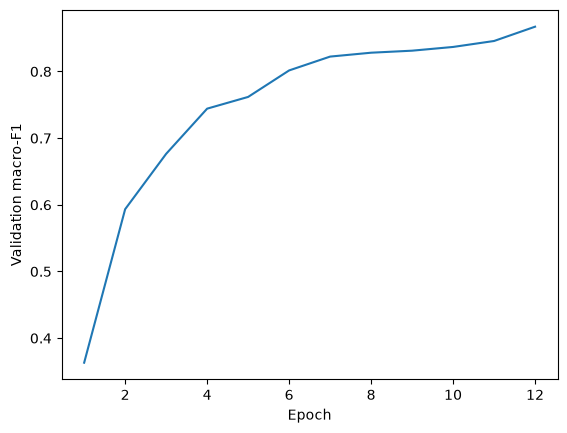

In [22]:
# 수정 금지

plt.plot([row['epoch'] for row in history], [row['val_f1'] for row in history])  # epoch별 검증 F1 그래프
plt.xlabel('Epoch')  # x축 이름
plt.ylabel('Validation macro-F1')  # y축 이름
plt.show()  # 그림 표시


In [23]:
# 수정 금지

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))  # 저장된 best 가중치를 다시 불러옴 (weights_only=True: 안전 로딩)
val_loss, val_f1 = evaluate(model, val_loader, loss_fn)  # 검증
print(f'[Final] Validation macro-F1: {val_f1:.4f}')  # 최종 macro-F1 출력 (채점 기준 값)

[Final] Validation macro-F1: 0.8672


## 제출
- 완성한 노트북 `.ipynb`
- Best 체크포인트 `outputs/F1_2_<수험번호>.pt`
- 실제로 실행한 validation 결과를 노트북에 남기세요.